# Vẽ các bước Gradient Descent của ví dụ tính tay (mục 5.1.3)

Hàm f(x) = (x + 2)^2 với x0 = 0, tốc độ học η = 0.25

x_t = [ 0.    -1.    -1.5   -1.75  -1.875]


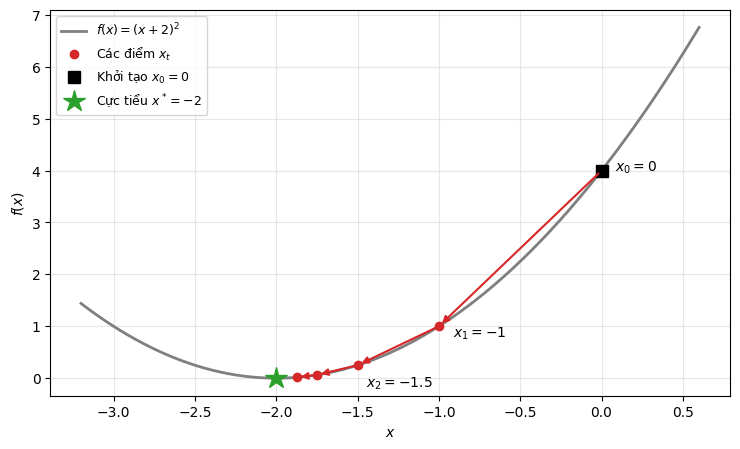

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

def f(x):
    return (x + 2)**2

def grad(x):
    """Đạo hàm f'(x)."""
    return 2 * x + 4

eta = 0.25                       # tốc độ học η
x_history = [0.0]                # dãy x_t, bắt đầu từ x0 = 0
for t in range(4):
    x_history.append(x_history[-1] - eta * grad(x_history[-1]))
x_history = np.array(x_history)
print('x_t =', x_history)

x_line = np.linspace(-3.2, 0.6, 400)
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.plot(x_line, f(x_line), color="#7F7F7F", lw=2, label=r"$f(x) = (x + 2)^2$")

# Mỗi mũi tên là một bước x_t -> x_{t+1} trên đồ thị
for x_now, x_next in zip(x_history[:-1], x_history[1:]):
    ax.annotate("", xy=(x_next, f(x_next)), xytext=(x_now, f(x_now)),
                arrowprops=dict(arrowstyle="-|>", color="#D62728", lw=1.5, shrinkA=3, shrinkB=3))
ax.plot(x_history, f(x_history), "o", color="#D62728", ms=6, label="Các điểm $x_t$")
ax.plot(x_history[0], f(x_history[0]), "s", color="black", ms=9, label="Khởi tạo $x_0 = 0$")
ax.plot(-2, 0, "*", color="#2CA02C", ms=16, label="Cực tiểu $x^* = -2$")

# Ghi nhãn ba điểm đầu, các điểm sau quá gần nhau
offsets = [(10, 0), (10, -8), (6, -16)]
for t, offset in enumerate(offsets):
    ax.annotate(f"$x_{t} = {x_history[t]:g}$", (x_history[t], f(x_history[t])),
                xytext=offset, textcoords="offset points", fontsize=10)

ax.set_xlabel("$x$"); ax.set_ylabel("$f(x)$"); ax.grid(alpha=0.3)
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
fig.savefig(IMAGES / "gd_steps.png", dpi=150)